In [1]:
# %% 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates 

from pathlib import Path

# Here we define the path to the data file as a string (str)
# Notice the 'r' in from of the quotes, this tells the computer
# to ignore spetial characters and read it as a string
path_to_file = r"/mnt/workspace/projects/tutorials/marama_2026/data/AMP501_2420560-0.txt"

if not isinstance(path_to_file, Path):
    if isinstance(path_to_file, str): 
        path_to_file = Path(path_to_file)
    else: 
        raise TypeError("path must be of type string or Path")

if not path_to_file.is_file():
    raise FileNotFoundError(f"The file {path_to_file.resolve()} could not be found on this machine")

# First we try to naively import the file using 'pandas.read_csv()'
# It shouldn't work exactly as you want it
df = pd.read_csv(path_to_file)

# .read_csv() can import more delimeter types than ','
df = pd.read_csv(path_to_file, sep="|")

# A DtypeWarning means that the data have conflicting datatypes
# This is definetely caused by the two header lines
df = pd.read_csv(path_to_file, sep="|", header=[0], skiprows=1, low_memory=False)

/tmp/ipykernel_793518/1016686393.py:28: DtypeWarning: Columns (2: State Code, 3: County Code, 4: Site ID, 5: Parameter, 6: POC, 7: Sample Duration, 8: Unit, 9: Method, 10: Date, 12: Sample Value, 14: Sampling Frequency, 15: Monitor Protocol (MP) ID, 16: Qualifier - 1, 17: Qualifier - 2, 18: Qualifier - 3, 19: Qualifier - 4, 20: Qualifier - 5, 21: Qualifier - 6, 22: Qualifier - 7, 23: Qualifier - 8, 24: Qualifier - 9, 25: Qualifier - 10, 26: Alternate Method Detectable Limit) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path_to_file, sep="|")


In [2]:
df.head()

,# RC,Action Code,State Code,County Code,Site ID,Parameter,POC,Unit,Method,Year,...,Qualifier - 3,Qualifier - 4,Qualifier - 5,Qualifier - 6,Qualifier - 7,Qualifier - 8,Qualifier - 9,Qualifier - 10,Alternate Method Detectable Limit,Uncertainty
RD,I,42.0,3.0,2.0,88101.0,2.0,1.0,105.0,636.0,20250101.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RD,I,42.0,3.0,2.0,88101.0,2.0,1.0,105.0,636.0,20250101.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RD,I,42.0,3.0,2.0,88101.0,2.0,1.0,105.0,636.0,20250101.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RD,I,42.0,3.0,2.0,88101.0,2.0,1.0,105.0,636.0,20250101.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RD,I,42.0,3.0,2.0,88101.0,2.0,1.0,105.0,636.0,20250101.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.tail()

,# RC,Action Code,State Code,County Code,Site ID,Parameter,POC,Unit,Method,Year,...,Qualifier - 3,Qualifier - 4,Qualifier - 5,Qualifier - 6,Qualifier - 7,Qualifier - 8,Qualifier - 9,Qualifier - 10,Alternate Method Detectable Limit,Uncertainty
RD,I,42.0,3.0,3007.0,88101.0,2.0,1.0,105.0,636.0,20251231.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RD,I,42.0,3.0,3007.0,88101.0,2.0,1.0,105.0,636.0,20251231.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RD,I,42.0,3.0,3007.0,88101.0,2.0,1.0,105.0,636.0,20251231.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RD,I,42.0,3.0,3007.0,88101.0,2.0,1.0,105.0,636.0,20251231.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
# 60264 records were written,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


That last line looks like it doesn't belong. Let's leave it out by a simple slice

In [4]:
df = pd.read_csv(path_to_file, sep="|", header=[0], low_memory=False)[:-1]

In [5]:
df.tail()

,# RD,Action Code,State Code,County Code,Site ID,Parameter,POC,Sample Duration,Unit,Method,...,Qualifier - 3,Qualifier - 4,Qualifier - 5,Qualifier - 6,Qualifier - 7,Qualifier - 8,Qualifier - 9,Qualifier - 10,Alternate Method Detectable Limit,Uncertainty
60260,RD,I,42,003,3007,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60261,RD,I,42,003,3007,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60262,RD,I,42,003,3007,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60263,RD,I,42,003,3007,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60264,RD,I,42,003,3007,88101,2,1,105,636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60265 entries, 0 to 60264
Data columns (total 28 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   # RD                               60265 non-null  str    
 1   Action Code                        60265 non-null  str    
 2   State Code                         60265 non-null  str    
 3   County Code                        60265 non-null  str    
 4   Site ID                            60265 non-null  str    
 5   Parameter                          60265 non-null  str    
 6   POC                                60265 non-null  str    
 7   Sample Duration                    60265 non-null  str    
 8   Unit                               60265 non-null  str    
 9   Method                             60265 non-null  str    
 10  Date                               60265 non-null  str    
 11  Start Time                         60265 non-null  str    
 12  S

The Data Types (dtype) are wrong for 'Year' (float) but correct (string) for 'Period'. We can changes this on import or after import. 

In [7]:
df["Date"] = df["Date"].astype(str)

In [8]:
df[["Date"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 60265 entries, 0 to 60264
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Date    60265 non-null  str  
dtypes: str(1)
memory usage: 470.9 KB


In [9]:
dtypes = {
    "Date": str,
    "Start Time": str,
}

df = pd.read_csv(path_to_file, sep="|", header=[0], low_memory=False, dtype=dtypes)[1:-1]

In [10]:
df[["Date", "Start Time"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 60264 entries, 1 to 60264
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Date        60264 non-null  str  
 1   Start Time  60264 non-null  str  
dtypes: str(2)
memory usage: 941.8 KB


To do any plotting we need to have this oriented by time. Current we have no datetime information. Just two string (Year, and Period). We can combine these as one string and then convert it to a datetime

In [11]:
df[["Date", "Start Time"]].head()

,Date,Start Time
1,20250101,00:00
2,20250101,01:00
3,20250101,02:00
4,20250101,03:00
5,20250101,04:00


In [12]:
df["Datetime"] = pd.to_datetime(
    df["Date"] + df["Start Time"],
    format="%Y%m%d%H:%M"
)

In [13]:
df[["Datetime"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 60264 entries, 1 to 60264
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Datetime  60264 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 470.9 KB


Now we can plot...

In [14]:
for i,val in df["Sample Value"].items():
    if not float(val): 
        print(i, val)

In [15]:
df["Sample Value"] = df["Sample Value"].astype(float)

<Axes: xlabel='Datetime'>

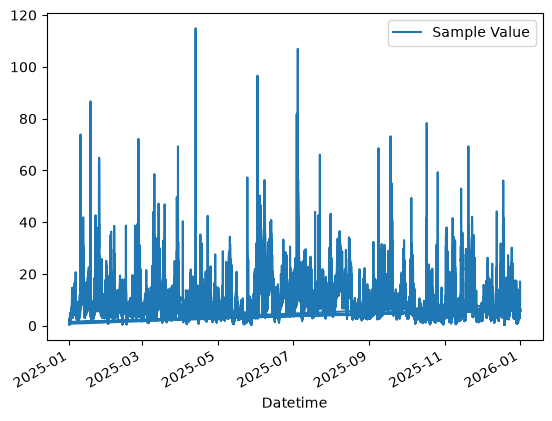

In [16]:
df.plot(x="Datetime", y="Sample Value")

We got a plot but wait.... are there multiple sites in this file? 

In [17]:
df["Site ID"].unique()

<StringArray>
['0002', '0008', '0064', '0067', '1008', '1301', '1376', '3007']
Length: 8, dtype: str

We should probably split things up by 'Site ID'. We could do mulitple plots (but there are lot many unique 'Site ID' or we could do a legend)

Let's use Matplotlib for this part...

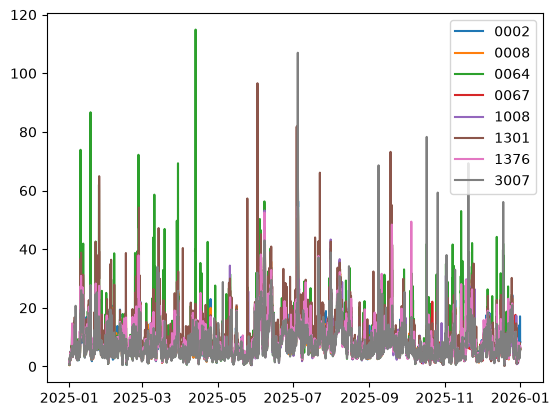

In [18]:
plt.figure()
for site in df["Site ID"].unique():
    df_site = df[df["Site ID"] == site][["Datetime", "Sample Value"]] 
    plt.plot(df_site["Datetime"], df_site["Sample Value"], label=site)
plt.legend()

What parameter is this? 

In [19]:
df["Parameter"].unique()

<StringArray>
['88101']
Length: 1, dtype: str

88101 is PM2.5

Let's make the plot look better. 

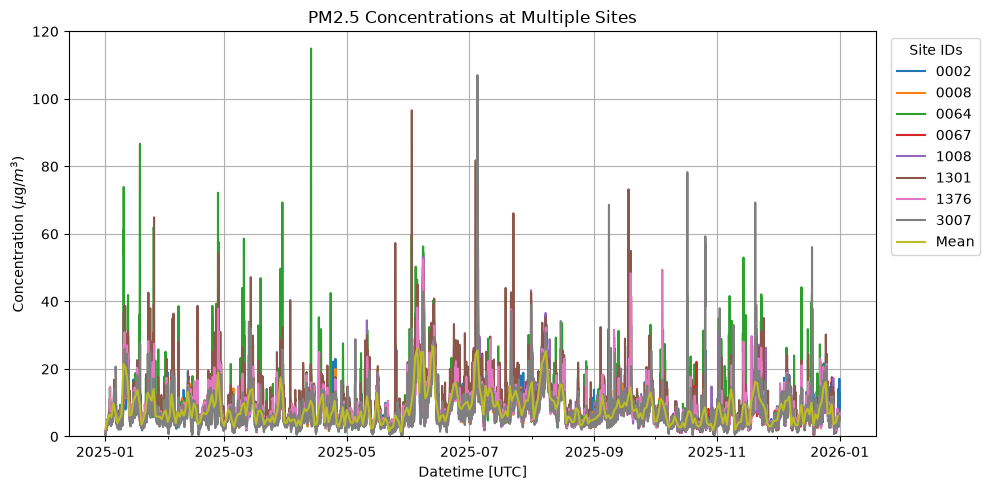

In [20]:
fig, ax = plt.subplots(figsize=(10, 5), layout="tight")
for site in df["Site ID"].unique():
    df_site = df[df["Site ID"] == site][["Datetime", "Sample Value"]] 
    ax.plot(df_site["Datetime"], df_site["Sample Value"], label=site)

mean = df.groupby(df["Datetime"].dt.date, as_index=False)["Sample Value"].mean()
ax.plot(mean["Datetime"], mean["Sample Value"], label="Mean")

plt.grid("both")
plt.ylabel(r"Concentration ($\mu\mathrm{g}/m^3$)")
plt.xlabel("Datetime [UTC]")
plt.title("PM2.5 Concentrations at Multiple Sites")

plt.ylim(0, 120)

ax.xaxis.set_minor_locator(mdates.MonthLocator())

plt.legend(title="Site IDs", bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

Let's do some analysis on this now. It looks like 2025-06 has some high values for several days across all sites. 

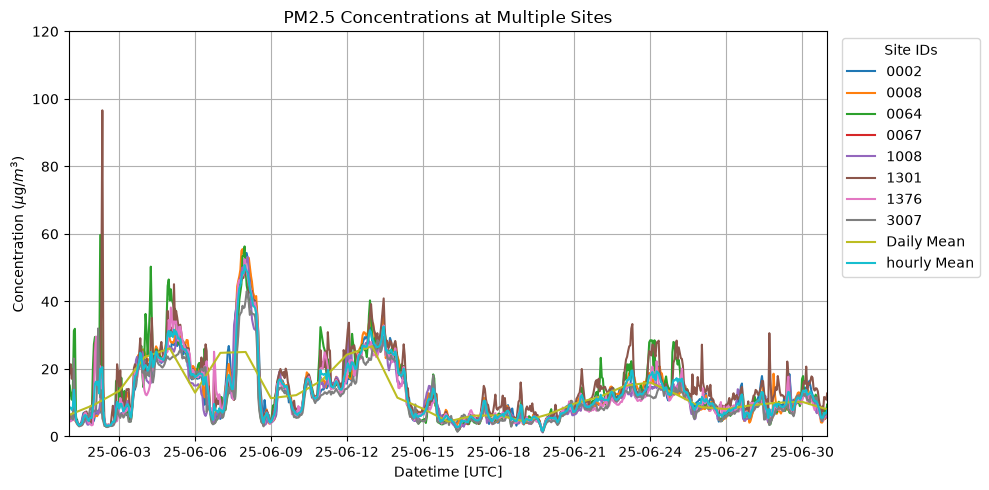

In [21]:
fig, ax = plt.subplots(figsize=(10, 5), layout="tight")
for site in df["Site ID"].unique():
    df_site = df[df["Site ID"] == site][["Datetime", "Sample Value"]] 
    ax.plot(df_site["Datetime"], df_site["Sample Value"], label=site)

daily_mean = df.groupby(df["Datetime"].dt.date, as_index=False)["Sample Value"].mean()
ax.plot(daily_mean["Datetime"], daily_mean["Sample Value"], label="Daily Mean")

# Hourly mean across all sites: one value for every hour
hourly_mean = df.groupby("Datetime", as_index=False)["Sample Value"].mean()
ax.plot(hourly_mean["Datetime"], hourly_mean["Sample Value"], label="hourly Mean")

plt.grid("both")
plt.ylabel(r"Concentration ($\mu\mathrm{g}/m^3$)")
plt.xlabel("Datetime [UTC]")
plt.title("PM2.5 Concentrations at Multiple Sites")

plt.ylim(0, 120)
plt.xlim(pd.Timestamp("2025-06-01"), pd.Timestamp("2025-07-01"))

ax.xaxis.set_major_formatter(mdates.DateFormatter('%y-%m-%d'))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))

plt.legend(title="Site IDs", bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()